# Project 01: BM25 with gene query expansion

**Research question:** does adding the official gene symbol and its synonyms from NCBI Gene
to the query improve BM25 on the TREC Genomics training queries?

**Hypothesis:** yes, because the gene names reduce vocabulary mismatch.
We measure MAP, P@10 and recall@1000.

Needs Elasticsearch 7.x on `http://127.0.0.1:9200` and `data01.zip` next to this notebook.

## 1. Data

The MEDLINE collection, the 38 training queries and their judgments.
The test queries have no judgments, so we don't use them.

In [1]:
from pathlib import Path
import csv
import json
import zipfile

from elasticsearch import Elasticsearch
from elasticsearch.helpers import bulk
import matplotlib.pyplot as plt
import pandas as pd
import pytrec_eval
from scipy.stats import binomtest, ttest_rel, wilcoxon

DATA = Path('data01')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
INDEX = 'fir01-project-bm25'
CORPUS = DATA / 'FIR-s05-medline.json'
TOPICS = DATA / 'FIR-s05-training-queries-simple.txt'
QRELS = DATA / 'FIR-s05-training-qrels.txt'

if not all(path.exists() for path in [CORPUS, TOPICS, QRELS]):
    with zipfile.ZipFile('data01.zip') as archive:
        archive.extractall()

topics = {}
with open(TOPICS, encoding='utf-8') as f:
    for line in f:
        qid, query = line.strip().split('\t')
        topics[qid] = query

relevant = {}
with open(QRELS, encoding='utf-8') as f:
    for line in f:
        qid, _, pmid, grade = line.split()
        if int(grade) > 0:
            relevant.setdefault(qid, set()).add(pmid)

print(len(topics), 'queries,', sum(len(docs) for docs in relevant.values()), 'relevant documents')
print('Example query:', topics['7'])

38 queries, 144 relevant documents
Example query: Janus kinase 2 (a protein tyrosine kinase) in Homo sapiens


## 2. Index

Title and abstract go into one field, `all`: standard analyzer (no stemming, no stopwords),
BM25 with k1 = 1.2 and b = 0.75, one shard. The index is built once and then reused.

In [2]:
es = Elasticsearch('http://127.0.0.1:9200', timeout=120)
print('Elasticsearch', es.info()['version']['number'])

settings = {
    'number_of_shards': 1,
    'number_of_replicas': 0,
    'similarity': {'retrieval': {'type': 'BM25', 'k1': 1.2, 'b': 0.75}},
}
mappings = {'properties': {
    'PMID': {'type': 'keyword'},
    'TI': {'type': 'text', 'copy_to': 'all'},
    'AB': {'type': 'text', 'copy_to': 'all'},
    'all': {'type': 'text', 'analyzer': 'standard', 'similarity': 'retrieval'},
}}

def documents():
    # The collection file alternates a bulk action line and a document line.
    with open(CORPUS, encoding='utf-8') as f:
        for action in f:
            doc = json.loads(next(f))
            yield {'_index': INDEX, '_id': json.loads(action)['index']['_id'],
                   'PMID': doc['PMID'], 'TI': doc.get('TI', ''), 'AB': doc.get('AB', '')}

if not es.indices.exists(index=INDEX):
    es.indices.create(index=INDEX, settings=settings, mappings=mappings)
    bulk(es, documents(), chunk_size=1000, request_timeout=120)
    es.indices.refresh(index=INDEX)

count = es.count(index=INDEX)['count']
assert count == 263080, f'Index has {count} documents, expected 263080: delete it and run again.'
print('Documents in index:', count)

Elasticsearch 7.17.29
Documents in index: 263080


## 3. Gene names from NCBI

For each query we picked the NCBI Gene record by hand from the gene name and organism.
Queries 13 and 46 mention another organism but ask for the human gene. Some genes were
renamed later (GOLPH2 is now GOLM1, YARS is now YARS1).

The table is copied from the NCBI `gene_info` files ([format](https://ftp.ncbi.nlm.nih.gov/gene/README))
of 29 October 2026, so NCBI updates don't change the results. `Symbol` is
`Symbol_from_nomenclature_authority`, or NCBI's `Symbol` if that is missing.
The download code is in the appendix.

In [3]:
GENE_DATA = r'''qid	GeneID	tax_id	Symbol	Synonyms
1	1026	9606	CDKN1A	CAP20|CDKN1|CIP1|MDA-6|P21|SDI1|WAF1|p21CIP1
3	2120	9606	ETV6	TEL|TEL/ABL|THC5
4	2252	9606	FGF7	HBGF-7|KGF
5	2741	9606	GLRA1	HKPX1|STHE
6	3119	9606	HLA-DQB1	CELIAC1|HLA-DQB|IDDM1
7	3717	9606	JAK2	JTK10
8	3973	9606	LHCGR	HHG|LCGR|LGR2|LH/CG-R|LH/CGR|LHR|LHRHR|LSH-R|ULG5
9	4504	9606	MT3	GIF|GIFB|GRIF|ZnMT3
10	5624	9606	PROC	APC|PC|PROC1|THPH3|THPH4
11	5879	9606	RAC1	MIG5|MRD48|Rac-1|TC-25|p21-Rac1
12	7168	9606	TPM1	C15orf13|CMD1Y|CMH3|HEL-S-265|HTM-alpha|LVNC9|TMSA
13	8322	9606	FZD4	CD344|EVR1|FEVR|FZD4S|Fz-4|Fz4|FzE4|GPCR|hFz4
14	8565	9606	YARS1	CMTDIC|IMNEPD2|TYRRS|YARS|YRS|YTS
15	9961	9606	MVP	LRP|VAULT1
16	11550	10090	Adra1d	Adra-1|Adra1|Adra1a|Gpcr8|Spr8|[a]1d|alpha1D-AR
18	12367	10090	Casp3	A830040C14Rik|AC-3|CASP-3|CC3|CPP-32|CPP32|Caspase-3|Lice|SCA-1|Yama|mldy
20	14103	10090	Fasl	APT1LG1|CD178|CD95-L|CD95L|Fas-L|Faslg|Tnfsf6|Tnlg1a|gld
22	16147	10090	Ihh	HHG-2
23	18803	10090	Plcg1	Cded|Plc-1|Plc-gamma1|Plcg-1
24	20439	10090	Siah2	Sinh2
25	21673	10090	Dntt	Tdt
27	24260	10116	Chrm3	-
28	24330	10116	Egr1	Krox-24|NGFI-A|Ngf1|Ngfi|zif-268
29	24385	10116	Gck	GLK|GLUKA|RNGK2
31	24806	10116	Tac1	PPTA3|Ppt5fl|RATPPTA3|TAC
32	24890	10116	Esr1	ER-alpha|Esr|RNESTROR
34	29131	10116	Cartpt	Cart
36	32080	7227	hop	4|CG1594|Dm JAK|DmHD-160|Dmel\CG1594|HD-160|HOP|Hop|Hop1|Hop2|Hpo|JAK|Jak|L4|Tum|Tum-1|d-jak|hop/JAK|jak|l(1)10Be|l(1)G18|l(1)L4|l(1)hop|msvl
37	34038	7227	Slob	CG13792|CG43756|CG6772|Dmel\CG43756|Dmel_CG13792|Dmel_CG6772|SLOB|slob
38	36054	7227	egr	BcDNA:RH51659|CG12919|Dmel\CG12919|EGR|Ect1|Egr|Eig|Eiger|Regg1|TNF|TNF-alpha|TNFalpha|darth|dt1|regg1
39	37386	7227	shg	CADH|CG3722|CT12481|Cad|CadE|Cadh|D E-cad|D-CAD2|D-cad|DCAD|DCAD2|DCad|DCad2|DE|DE Cad|DE Cadh|DE-CAD|DE-CAD2|DE-Cad|DE-Cad2|DE-Cadh|DE-Cadherin|DE-cad|DE-cadh|DE-cadherin|DEC|DECAD|DECad|DECadh|DE[cyto]|DEcad|De-Cad|Dmel\CG3722|E-CAD|E-Ca|E-Cad|E-Cadh|E-Cadherin|E-cad|E-cadherin|ECAD|ECad|ECad2|ECadh|ECadherin|Ecad|N-cad|Shg|Shotgun|cad|cadh|com5|dE-cadherin|dEcad|de-cad|e-cad|ecad|gp150|l(2)10469|l(2)k03401|l(2)k10220|shg/DE-Cad
40	42428	7227	Stat92E	CG4257|D-STAT|D-Stat|D-stat|D-stat/stat92E|DRODSRC|DSRC|DSTAT|DmSTAT|Dmel\CG4257|Dst|Dstat|Dstat 92E|Dstat92E|SD-stat|STAT|STAT 92E|STAT92|STAT92E|STAT92e|Sta92E|Stat|Stat1alpha-like|Stat92|Stat92e|Stat9E|d-STAT|dSTAT|dSTAT92E|dSTAT92E/marelle|dstat|l(3)06346|l(3)j6C8|mrL|mrl|mrl stat92E|pSTAT|pSTAT92E|stat|stat92|stat92E|stat92e|stat[92E]
42	42896	7227	crb	0509/20|1384/04|CG6383|CRB|CT19912|Crb|Crbs|Crumbs|DmCrb|Dmel\CG6383|crumb|far|l(3)07207|l(3)S050920|l(3)S058104|l(3)j1B5
44	51280	9606	GOLM1	C9orf155|GOLPH2|GP73|HEL46|PSEC0257|bA379P1.3
45	51429	9606	SNX9	SDP1|SH3PX1|SH3PXD3A|WISP
46	56172	9606	ANKH	ANK|CCAL2|CMDJ|CPPDD|HANK|MANK|SLC62A1
48	64421	9606	DCLRE1C	A-SCID|DCLREC1C|RS-SCID|SCIDA|SNM1C
50	81819	10116	Pax8	-
'''

genes = {row['qid']: row for row in csv.DictReader(GENE_DATA.splitlines(), delimiter='\t')}

gene_table = pd.DataFrame(genes.values())
gene_table.insert(1, 'query', gene_table['qid'].map(topics))
gene_table[['qid', 'query', 'GeneID', 'tax_id', 'Symbol']]

,qid,query,GeneID,tax_id,Symbol
0,1,"""cyclin-dependent kinase inhibitor 1A (p21, Ci...",1026,9606,CDKN1A
1,3,ets variant gene 6 (TEL oncogene) in Homo sapiens,2120,9606,ETV6
2,4,fibroblast growth factor 7 (keratinocyte growt...,2252,9606,FGF7
3,5,"""glycine receptor, alpha 1 (startle disease/hy...",2741,9606,GLRA1
4,6,"""major histocompatibility complex, class II, D...",3119,9606,HLA-DQB1
5,7,Janus kinase 2 (a protein tyrosine kinase) in ...,3717,9606,JAK2
6,8,luteinizing hormone/choriogonadotropin recepto...,3973,9606,LHCGR
7,9,metallothionein 3 (growth inhibitory factor (n...,4504,9606,MT3
8,10,protein C (inactivator of coagulation factors ...,5624,9606,PROC
9,11,"""ras-related C3 botulinum toxin substrate 1 (r...",5879,9606,RAC1


## 4. Query expansion

The expanded query is the original query plus the symbol and each synonym as extra OR clauses,
all with weight 1. Names of more than one token must match as a phrase. We skip names without
letters (`-`, `4`), duplicates after analysis, and names already in the query.
Nothing is tuned on the judgments.

In [4]:
def analyze(text):
    result = es.indices.analyze(index=INDEX, body={'field': 'all', 'text': text})
    return ' '.join(token['token'] for token in result['tokens'])

def expansion_terms(query, gene):
    query_tokens = ' ' + analyze(query) + ' '
    added, seen = [], set()
    for name in [gene['Symbol']] + gene['Synonyms'].split('|'):
        tokens = analyze(name)
        if not any(c.isalpha() for c in tokens):
            continue  # missing or numbers only
        if tokens in seen or ' ' + tokens + ' ' in query_tokens:
            continue  # duplicate, or already in the query
        added.append(name)
        seen.add(tokens)
    return added

def make_query(query, aliases=()):
    clauses = [{'match': {'all': query}}]
    clauses += [{'match_phrase': {'all': alias}} for alias in aliases]
    return {'bool': {'should': clauses}}

expansions = {qid: expansion_terms(query, genes[qid]) for qid, query in topics.items()}

print('Query 7:', topics['7'])
print('Added:', expansions['7'])
print(json.dumps(make_query(topics['7'], expansions['7']), indent=2))

Query 7: Janus kinase 2 (a protein tyrosine kinase) in Homo sapiens
Added: ['JAK2', 'JTK10']
{
  "bool": {
    "should": [
      {
        "match": {
          "all": "Janus kinase 2 (a protein tyrosine kinase) in Homo sapiens"
        }
      },
      {
        "match_phrase": {
          "all": "JAK2"
        }
      },
      {
        "match_phrase": {
          "all": "JTK10"
        }
      }
    ]
  }
}


In [5]:
pd.DataFrame({'qid': list(expansions),
              'symbol': [genes[qid]['Symbol'] for qid in expansions],
              'added names': [' | '.join(names) for names in expansions.values()]})

,qid,symbol,added names
0,1,CDKN1A,CDKN1A | CAP20 | CDKN1 | MDA-6 | SDI1 | WAF1 |...
1,3,ETV6,ETV6 | TEL/ABL | THC5
2,4,FGF7,FGF7 | HBGF-7 | KGF
3,5,GLRA1,GLRA1 | HKPX1 | STHE
4,6,HLA-DQB1,HLA-DQB1 | CELIAC1 | HLA-DQB | IDDM1
5,7,JAK2,JAK2 | JTK10
6,8,LHCGR,LHCGR | HHG | LCGR | LGR2 | LH/CG-R | LH/CGR |...
7,9,MT3,MT3 | GIF | GIFB | GRIF | ZnMT3
8,10,PROC,PROC | APC | PC | PROC1 | THPH3 | THPH4
9,11,RAC1,MIG5 | MRD48 | Rac-1 | TC-25 | p21-Rac1


## 5. Runs

Top 1,000 documents per query with the same search for both runs; only the query differs.
Ties are broken by PMID. The runs are saved in TREC format.

In [6]:
def search(query, aliases=()):
    response = es.search(index=INDEX, query=make_query(query, aliases), size=1000,
                         _source=['PMID'], sort=[{'_score': 'desc'}, {'PMID': 'asc'}])
    assert not response['timed_out'] and response['_shards']['failed'] == 0, 'Incomplete search result'
    return [(hit['_source']['PMID'], hit['_score']) for hit in response['hits']['hits']]

runs = {}
for name in ['baseline', 'expanded']:
    runs[name] = {}
    with open(RESULTS / f'{name}.run', 'w', encoding='utf-8') as f:
        for qid, query in topics.items():
            results = search(query, expansions[qid] if name == 'expanded' else [])
            runs[name][qid] = [pmid for pmid, score in results]
            for rank, (pmid, score) in enumerate(results, 1):
                f.write(f'{qid} Q0 {pmid} {rank} {score:.12g} {name}\n')
    print('Wrote', RESULTS / f'{name}.run')

Wrote results\baseline.run


Wrote results\expanded.run


## 6. Evaluation

AP divides by all relevant documents of a query, also the unretrieved ones; P@10 always
divides by 10. The judgments only list relevant documents, so unjudged ones count as not relevant.

In [7]:
def average_precision(relevant, ranking):
    hits, total = 0, 0.0
    for rank, pmid in enumerate(ranking, 1):
        if pmid in relevant:
            hits += 1
            total += hits / rank
    return total / len(relevant)

def precision_at_10(relevant, ranking):
    return len(relevant & set(ranking[:10])) / 10

def recall(relevant, ranking):
    return len(relevant & set(ranking)) / len(relevant)

rows = []
for qid in topics:
    rel = relevant[qid]
    row = {'qid': qid, 'query': topics[qid], 'symbol': genes[qid]['Symbol'],
           'known_relevant': len(rel), 'added_aliases': len(expansions[qid])}
    for name, run in runs.items():
        row[f'{name}_AP'] = average_precision(rel, run[qid])
        row[f'{name}_P10'] = precision_at_10(rel, run[qid])
        row[f'{name}_recall1000'] = recall(rel, run[qid])
    row['AP_change'] = row['expanded_AP'] - row['baseline_AP']
    rows.append(row)
per_query = pd.DataFrame(rows)
per_query.to_csv(RESULTS / 'per-query-metrics.csv', index=False)

summary = pd.DataFrame({name: {'MAP': per_query[f'{name}_AP'].mean(),
                               'P@10': per_query[f'{name}_P10'].mean(),
                               'mean recall@1000': per_query[f'{name}_recall1000'].mean()}
                        for name in runs}).T
summary.loc['expanded - baseline'] = summary.loc['expanded'] - summary.loc['baseline']
summary.to_csv(RESULTS / 'metrics-summary.csv')
summary

,MAP,P@10,mean recall@1000
baseline,0.133170,0.047368,0.737607
expanded,0.266745,0.097368,0.920004
expanded - baseline,0.133575,0.050000,0.182397


Check against `trec_eval`.

In [8]:
qrels = {qid: {pmid: 1 for pmid in docs} for qid, docs in relevant.items()}
evaluator = pytrec_eval.RelevanceEvaluator(qrels, {'map', 'P.10', 'recall.1000'})
ours = per_query.set_index('qid')
for name, run in runs.items():
    # Rank-based scores, so trec_eval keeps our tie order.
    scores = {qid: {pmid: float(1000 - i) for i, pmid in enumerate(docs)} for qid, docs in run.items()}
    for qid, ref in evaluator.evaluate(scores).items():
        assert abs(ref['map'] - ours.loc[qid, f'{name}_AP']) < 1e-12
        assert abs(ref['P_10'] - ours.loc[qid, f'{name}_P10']) < 1e-12
        assert abs(ref['recall_1000'] - ours.loc[qid, f'{name}_recall1000']) < 1e-12
print('AP, P@10 and recall@1000 match trec_eval for all queries.')

AP, P@10 and recall@1000 match trec_eval for all queries.


### AP change per query

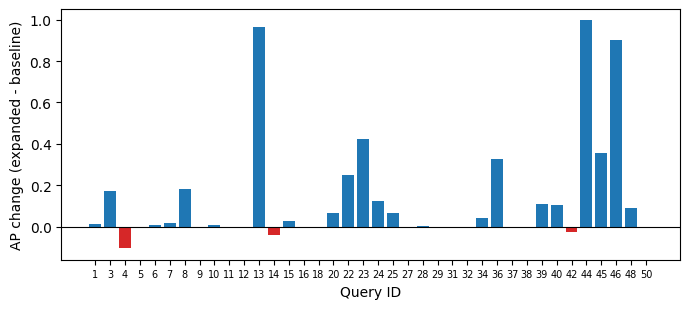

In [9]:
plot_data = per_query.sort_values('qid', key=lambda ids: ids.astype(int))
colors = ['tab:blue' if change > 0 else 'tab:red' for change in plot_data['AP_change']]
plt.rcParams['pdf.fonttype'] = 42  # TrueType instead of Type 3 fonts, for the ACM paper

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(plot_data['qid'], plot_data['AP_change'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Query ID')
ax.set_ylabel('AP change (expanded - baseline)')
ax.tick_params(axis='x', labelsize=7)
fig.tight_layout()
fig.savefig(RESULTS / 'ap-change-by-query.pdf')
fig.savefig(RESULTS / 'ap-change-by-query.png', dpi=300)
plt.show()

## 7. Significance tests

Paired two-sided tests on per-query AP, alpha = 0.05. Wilcoxon signed-rank is the main test;
the sign test and t-test are for comparison. Wilcoxon and the sign test drop unchanged queries.

Wilcoxon was the main test in our 27 October plan. The first version of this notebook only ran
the sign test, and Wilcoxon was added back after we had seen the results, so we report all three.

In [10]:
baseline_ap, expanded_ap = per_query['baseline_AP'], per_query['expanded_AP']
wins = int((expanded_ap > baseline_ap).sum())
losses = int((expanded_ap < baseline_ap).sum())
print(f'AP higher for {wins} queries, lower for {losses}, unchanged for {len(per_query) - wins - losses}')

w = wilcoxon(expanded_ap, baseline_ap)
sign = binomtest(wins, wins + losses)
t = ttest_rel(expanded_ap, baseline_ap)
tests = pd.DataFrame({'test': ['Wilcoxon signed-rank', 'Exact sign test', 'Paired t-test'],
                      'statistic': [w.statistic, sign.statistic, t.statistic],
                      'p_value': [w.pvalue, sign.pvalue, t.pvalue]})
tests['p < 0.05'] = tests['p_value'] < 0.05
tests.to_csv(RESULTS / 'significance-tests.csv', index=False)
tests

AP higher for 22 queries, lower for 10, unchanged for 6


,test,statistic,p_value,p < 0.05
0,Wilcoxon signed-rank,79.000000,0.000542,True
1,Exact sign test,0.687500,0.050102,False
2,Paired t-test,3.065985,0.004039,True


## 8. Per-query results

Queries by AP change, then the ranks of all relevant documents (empty = not in the top 1,000)
and the ones found by only one run.

In [11]:
top3 = per_query.nlargest(3, 'AP_change')
print(f"Queries {', '.join(top3['qid'])} give {top3['AP_change'].sum() / per_query['AP_change'].sum():.1%} "
      'of the total AP change.')
per_query.sort_values('AP_change', ascending=False)[
    ['qid', 'symbol', 'added_aliases', 'baseline_AP', 'expanded_AP', 'AP_change']]

Queries 44, 13, 46 give 56.4% of the total AP change.


,qid,symbol,added_aliases,baseline_AP,expanded_AP,AP_change
33,44,GOLM1,7,0.003472,1.000000,0.996528
11,13,FZD4,10,0.034483,1.000000,0.965517
35,46,ANKH,8,0.100000,1.000000,0.900000
18,23,Plcg1,5,0.015106,0.440669,0.425563
34,45,SNX9,5,0.642857,1.000000,0.357143
27,36,hop,20,0.509091,0.833333,0.324242
17,22,Ihh,2,0.035461,0.284722,0.249261
6,8,LHCGR,10,0.020372,0.202381,0.182009
1,3,ETV6,3,0.192345,0.365373,0.173028
19,24,Siah2,2,0.000000,0.125000,0.125000


In [12]:
rank_rows = []
for qid in topics:
    baseline_rank = {pmid: rank for rank, pmid in enumerate(runs['baseline'][qid], 1)}
    expanded_rank = {pmid: rank for rank, pmid in enumerate(runs['expanded'][qid], 1)}
    for pmid in sorted(relevant[qid]):
        rank_rows.append({'qid': qid, 'PMID': pmid, 'baseline_rank': baseline_rank.get(pmid),
                          'expanded_rank': expanded_rank.get(pmid)})
ranks = pd.DataFrame(rank_rows)
ranks.to_csv(RESULTS / 'judged-document-ranks.csv', index=False)

in_baseline, in_expanded = ranks['baseline_rank'].notna(), ranks['expanded_rank'].notna()
print(f'Relevant documents in the top 1,000: baseline {in_baseline.sum()}, '
      f'expanded {in_expanded.sum()}, out of {len(ranks)}')
ranks[in_baseline != in_expanded]

Relevant documents in the top 1,000: baseline 104, expanded 123, out of 144


,qid,PMID,baseline_rank,expanded_rank
12,1,12025230,NaN,71.0
35,3,12393285,NaN,17.0
52,6,12358858,NaN,272.0
54,7,12223098,NaN,60.0
62,10,12029084,NaN,76.0
65,10,12091344,NaN,64.0
68,10,12407115,759.0,NaN
83,15,12612883,NaN,38.0
89,20,11695234,NaN,35.0
91,20,12050361,NaN,6.0


## 9. Which names cause the changes

For the three biggest gains (44, 13, 46), the three biggest losses (4, 14, 42) and query 10
(the only one that loses a relevant document), we rerun the query with each name alone and
with all names except that one. This is after-the-fact analysis; the runs above don't change.

In [13]:
def ap_with(qid, aliases):
    return average_precision(relevant[qid], [pmid for pmid, score in search(topics[qid], aliases)])

alias_rows = []
for qid in ['44', '13', '46', '4', '14', '42', '10']:
    aliases = expansions[qid]
    for alias in aliases:
        alias_rows.append({
            'qid': qid, 'symbol': genes[qid]['Symbol'], 'alias': alias,
            'baseline_AP': ours.loc[qid, 'baseline_AP'],
            'expanded_AP': ours.loc[qid, 'expanded_AP'],
            'only_this_alias_AP': ap_with(qid, [alias]),
            'without_this_alias_AP': ap_with(qid, [a for a in aliases if a != alias]),
        })
alias_effects = pd.DataFrame(alias_rows)
alias_effects.to_csv(RESULTS / 'alias-effects.csv', index=False)
alias_effects

,qid,symbol,alias,baseline_AP,expanded_AP,only_this_alias_AP,without_this_alias_AP
0,44,GOLM1,GOLM1,0.003472,1.000000,0.003472,1.000000
1,44,GOLM1,C9orf155,0.003472,1.000000,0.003472,1.000000
2,44,GOLM1,GOLPH2,0.003472,1.000000,0.003472,1.000000
3,44,GOLM1,GP73,0.003472,1.000000,1.000000,0.003472
4,44,GOLM1,HEL46,0.003472,1.000000,0.003472,1.000000
5,44,GOLM1,PSEC0257,0.003472,1.000000,0.003472,1.000000
6,44,GOLM1,bA379P1.3,0.003472,1.000000,0.003472,1.000000
7,13,FZD4,FZD4,0.034483,1.000000,1.000000,1.000000
8,13,FZD4,CD344,0.034483,1.000000,0.034483,1.000000
9,13,FZD4,EVR1,0.034483,1.000000,0.500000,1.000000


## 10. Limitations

- Incomplete judgments: unjudged documents count as not relevant.
- Gene records were picked by hand, and some synonyms are ambiguous (e.g. PC and APC in query 10).
- The NCBI names are from 2026, the abstracts more than 20 years older.
- All added names have the same weight.
- Only 38 queries, and three of them give over half of the AP gain.
- We looked at the training queries while building the system, so this is exploratory,
  not a test on unseen data.
- Run with Python 3.12 and Elasticsearch 7.17.29; not tested on the course VM's 7.9.

## Appendix: download the NCBI records

Set `DOWNLOAD = True` to fetch the current NCBI files and show the records used above.
NCBI updates them, so they may differ from the table in section 3.

In [14]:
import gzip
from urllib.request import urlretrieve

DOWNLOAD = False
NCBI = 'https://ftp.ncbi.nlm.nih.gov/gene/DATA/GENE_INFO/'
FILES = ['Mammalia/Homo_sapiens', 'Mammalia/Mus_musculus',
         'Mammalia/Rattus_norvegicus', 'Invertebrates/Drosophila_melanogaster']

if DOWNLOAD:
    wanted = {gene['GeneID'] for gene in genes.values()}
    current = []
    for name in FILES:
        path, _ = urlretrieve(NCBI + name + '.gene_info.gz')
        with gzip.open(path, 'rt', encoding='utf-8') as f:
            for row in csv.DictReader(f, delimiter='\t'):
                if row['GeneID'] in wanted:
                    official = row['Symbol_from_nomenclature_authority']
                    current.append({'GeneID': row['GeneID'], 'tax_id': row['#tax_id'],
                                    'Symbol': row['Symbol'] if official == '-' else official,
                                    'Synonyms': row['Synonyms']})
    display(pd.DataFrame(current))